# Visual defect inspection: a statistical and machine-learning analysis

**Author:** Claire Chen · [github.com/Clairechen163/visual-defect-inspection](https://github.com/Clairechen163/visual-defect-inspection)

A factory needs to decide, part by part, whether a manufactured component has a **scratch**, **discoloration** or a **chip**. This notebook goes from a rule-based computer-vision baseline to machine-learning models built from scratch, then to the questions a business actually asks:

| Section | Question | Methods |
|---|---|---|
| 1 | What does the data look like? | simulation design, EDA, feature distributions, correlation |
| 2 | How good is the rule-based baseline? | sensitivity / specificity trade-off |
| 3 | Can a model fix the trade-off? | softmax regression and a neural network, both written in NumPy |
| 4 | Is the better model *really* better? | repeated grouped cross-validation, corrected resampled t-test |
| 5 | How much labelled data do we need? | learning curve |
| 6 | What threshold should the factory use, and what is it worth? | ROC / PR curves, expected-cost decision analysis, bootstrap CI |
| 7 | How do we know when the process itself goes wrong? | statistical process control (p-chart), Pareto analysis |

> All data is **synthetic**, generated with known ground truth (see §1). The numbers show the method works; they are not a claim about a specific real production line.

In [1]:
import json, time, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, RUN, FIG = ROOT / "data" / "hard", ROOT / "models" / "notebook_run", ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

from defect_inspector import Inspector, InspectionConfig, load_image, annotate
from defect_inspector.synth import generate_dataset, generate_sample
from defect_inspector.ml import CLASSES, PatchClassifier
from defect_inspector.ml.features import FEATURE_NAMES
from defect_inspector.ml.dataset import extract_patches, group_split
from defect_inspector.ml import train as mltrain, validation, decision
from defect_inspector import spc
from defect_inspector.ml.plots import _style, SURFACE, INK, INK2, GRID, BLUE, ORANGE, DIV, SEQ

_style()
plt.rcParams["figure.dpi"] = 110
AQUA, YELLOW = "#1baf7a", "#eda100"
CLASS_COLORS = dict(zip(CLASSES, [BLUE, ORANGE, AQUA, YELLOW]))
def save(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")
SEED = 0

## 1. Data

### 1.1 Simulation design

There are no labelled factory images, so I **simulate** them. A simulation means every label is known exactly, and the difficulty can be controlled. Each image shows one machined part (a disc or a rounded rectangle) with a brushed-metal texture and uneven lighting. Then:

* 30% of parts are good. The rest get one or two of each defect type, chosen at random.
* **Defect intensity** is drawn from U(0.25, 1), so some scratches are faint and some stains pale, which makes the task realistically hard.
* **Nuisances** are added: Poisson(2) per image of dust specks, glare and short machining marks. They are *not* defects, but they look like defects. A useful inspector must ignore them.

In [2]:
t0 = time.time()
if not (DATA / "labels.json").exists():
    generate_dataset(DATA, n=400, seed=11, min_intensity=0.25, nuisance_rate=2.0)
labels = json.loads((DATA / "labels.json").read_text())
n_def = sum(bool(v) for v in labels.values())
print(f"{len(labels)} images, {n_def} defective ({n_def/len(labels):.0%}), generated in {time.time()-t0:.0f}s")

examples = [("Good part", [], 1.0, 0, 1), ("Faint scratch", ["scratch"], 0.35, 0, 2),
            ("Pale discoloration", ["discoloration"], 0.4, 0, 3), ("Small chip", ["chip"], 0.3, 0, 4),
            ("Good part + nuisances", [], 1.0, 5, 5), ("Clear defects", ["scratch", "discoloration", "chip"], 1.0, 0, 42)]
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
for ax, (title, d, inten, nn, seed) in zip(axes, examples):
    img, _ = generate_sample(np.random.default_rng(seed), d, inten, n_nuisance=nn)
    ax.imshow(img[60:452, 60:452, ::-1]); ax.set_title(title, loc="left", fontsize=10); ax.axis("off")
save(fig, "examples.png")

400 images, 288 defective (72%), generated in 0s


### 1.2 From images to a modelling table

For the models, each candidate region becomes a **64×64 patch** with one of four labels: good, scratch, discoloration or chip. Nuisances and random spots on the part's surface and edge are labelled *good*. Edge spots matter: without them, a model could learn that "anything on the edge is a chip".

Each patch is described in two ways:
* **18 statistical features**, each designed for one defect type: colour difference ΔE from the part's normal colour (discoloration), line strength and elongation (scratch), and concavity of the outline (chip).
* **Raw pixels**: a 24×24 colour image, so the model has to discover its own features.

**The split is by image, not by patch.** Patches from the same image share lighting and texture. Splitting patches at random would leak information from training to test and overstate accuracy.

In [3]:
ps = extract_patches(DATA, seed=SEED)
train, val, test = group_split(ps, seed=SEED)
counts = np.bincount(ps.y, minlength=4)
print(f"{len(ps)} patches from {len(np.unique(ps.image))} images")
print(f"split by image -> train {len(np.unique(train.image))} / val {len(np.unique(val.image))} / test {len(np.unique(test.image))} images")
print("no image in two splits:", not (set(train.image) & set(test.image)) and not (set(train.image) & set(val.image)))
dict(zip(CLASSES, counts.tolist()))

2980 patches from 400 images
split by image -> train 240 / val 80 / test 80 images
no image in two splits: True


{'good': 2397, 'scratch': 193, 'discoloration': 181, 'chip': 209}

### 1.3 Exploratory analysis

Four classes, heavily imbalanced (most patches are good). That's why **macro-F1** is reported alongside accuracy (it averages the F1 of each class, so a model can't score well just by predicting "good"), and why the models use **class-weighted loss**.

In [4]:
key = ["dE_mean", "line_p99", "concavity_depth", "grad_mean"]
nice = {"dE_mean": "Colour difference ΔE (mean)", "line_p99": "Line response (99th pct)",
        "concavity_depth": "Outline concavity depth (px)", "grad_mean": "Mean gradient"}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
rng = np.random.default_rng(0)
for ax, f in zip(axes, key):
    j = FEATURE_NAMES.index(f)
    for k, c in enumerate(CLASSES):
        v = ps.features[ps.y == k, j]
        v = v[rng.permutation(len(v))[:250]]
        ax.scatter(v, k + rng.uniform(-0.25, 0.25, len(v)), s=8, color=CLASS_COLORS[c], alpha=0.55, lw=0)
        ax.plot([np.median(v)] * 2, [k - 0.35, k + 0.35], color=INK, lw=2)
    ax.set_yticks(range(4), CLASSES if f == key[0] else [])
    ax.set_title(nice[f], loc="left", fontsize=10); ax.grid(axis="x", color=GRID, lw=0.6)
    if f in ("concavity_depth",): ax.set_xscale("symlog")
fig.suptitle("Each feature separates the class it was designed for (black bar = median)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "eda_features.png")

In [5]:
C = np.corrcoef(ps.features.T)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(C, cmap=DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURE_NAMES)), FEATURE_NAMES, rotation=90, fontsize=8)
ax.set_yticks(range(len(FEATURE_NAMES)), FEATURE_NAMES, fontsize=8)
for s in ax.spines.values(): s.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="Pearson r")
ax.set_title("Feature correlation: the colour features form a correlated block", loc="left", fontsize=10)
save(fig, "eda_correlation.png")
hi = [(FEATURE_NAMES[i], FEATURE_NAMES[j], round(C[i, j], 2)) for i in range(18) for j in range(i+1, 18) if abs(C[i, j]) > 0.9]
print("Pairs with |r| > 0.9:", hi)

Pairs with |r| > 0.9: [('dE_mean', 'dE_frac_gt8', np.float64(0.94)), ('concavity_fraction', 'concavity_depth', np.float64(0.96))]


The colour features are strongly correlated with each other (multicollinearity). For prediction that's acceptable, but it means individual softmax coefficients within that block should be read with caution: the model can shift weight between correlated features with little change in fit. L2 regularisation keeps those coefficients stable.

## 2. Baseline: rule-based inspection

The rule-based detectors use fixed thresholds. **Default** thresholds are conservative; **high-sensitivity** thresholds catch faint defects but also react to nuisances. Results are image-level PASS/FAIL on the 80 test images.

In [6]:
report = mltrain.run(DATA, RUN, seed=SEED, verbose=False)
comp = report["inspector_comparison"]
rows = [(k, v["accuracy"]["value"], v["escape_rate"]["value"], v["false_reject_rate"]["value"]) for k, v in comp.items()]
print(f"{'setup':32s} {'accuracy':>9s} {'defective passed':>17s} {'good rejected':>14s}")
for r in rows[:2]:
    print(f"{r[0]:32s} {r[1]:9.1%} {r[2]:17.1%} {r[3]:14.1%}")

setup                             accuracy  defective passed  good rejected
Rules (default)                      86.2%             19.3%           0.0%
Rules (high sensitivity)             86.2%              1.8%          43.5%


Neither threshold setting is acceptable: the default passes about 1 in 5 defective parts, and high sensitivity rejects over 40% of good ones. **Changing the threshold alone can't fix this;** the rules need more information about what they've found.

## 3. Models: softmax regression vs. a neural network

The idea is to run the rules at high sensitivity, then let a classifier look at each candidate and discard the false alarms.

**Softmax regression** (multinomial logistic regression) models
$P(y=k\mid x)=\dfrac{e^{w_k^\top x+b_k}}{\sum_j e^{w_j^\top x+b_j}}$ and minimises cross-entropy + L2.
**The neural network** stacks Linear → ReLU → Dropout layers before the softmax, which lets it learn non-linear boundaries.
Both are implemented from scratch (`ml/softmax.py`, `ml/mlp.py`): hand-written gradients and backpropagation, Adam, early stopping and class weights. Both pass a numerical gradient check in the test suite.

Each model is trained on two inputs (features vs. raw pixels), which gives a 2×2 design.

In [7]:
print(f"{'model':22s} {'params':>8s} {'accuracy [95% CI]':>24s} {'macro-F1':>9s} {'ECE':>6s}")
for k, m in report["models"].items():
    lo, hi = m["test_accuracy_ci95"]
    print(f"{k:22s} {m['n_params']:8,d} {m['test_accuracy']:8.1%} [{lo:.1%}, {hi:.1%}] {m['test_macro_f1']:9.3f} {m['ece']:6.3f}")

model                    params        accuracy [95% CI]  macro-F1    ECE
softmax_features             76    97.6% [96.0%, 98.9%]     0.949  0.029
mlp_features              3,428    98.8% [97.7%, 99.7%]     0.976  0.006
softmax_pixels            9,220    85.4% [82.6%, 88.2%]     0.647  0.063
mlp_pixels              303,556    92.7% [90.1%, 95.0%]     0.817  0.043


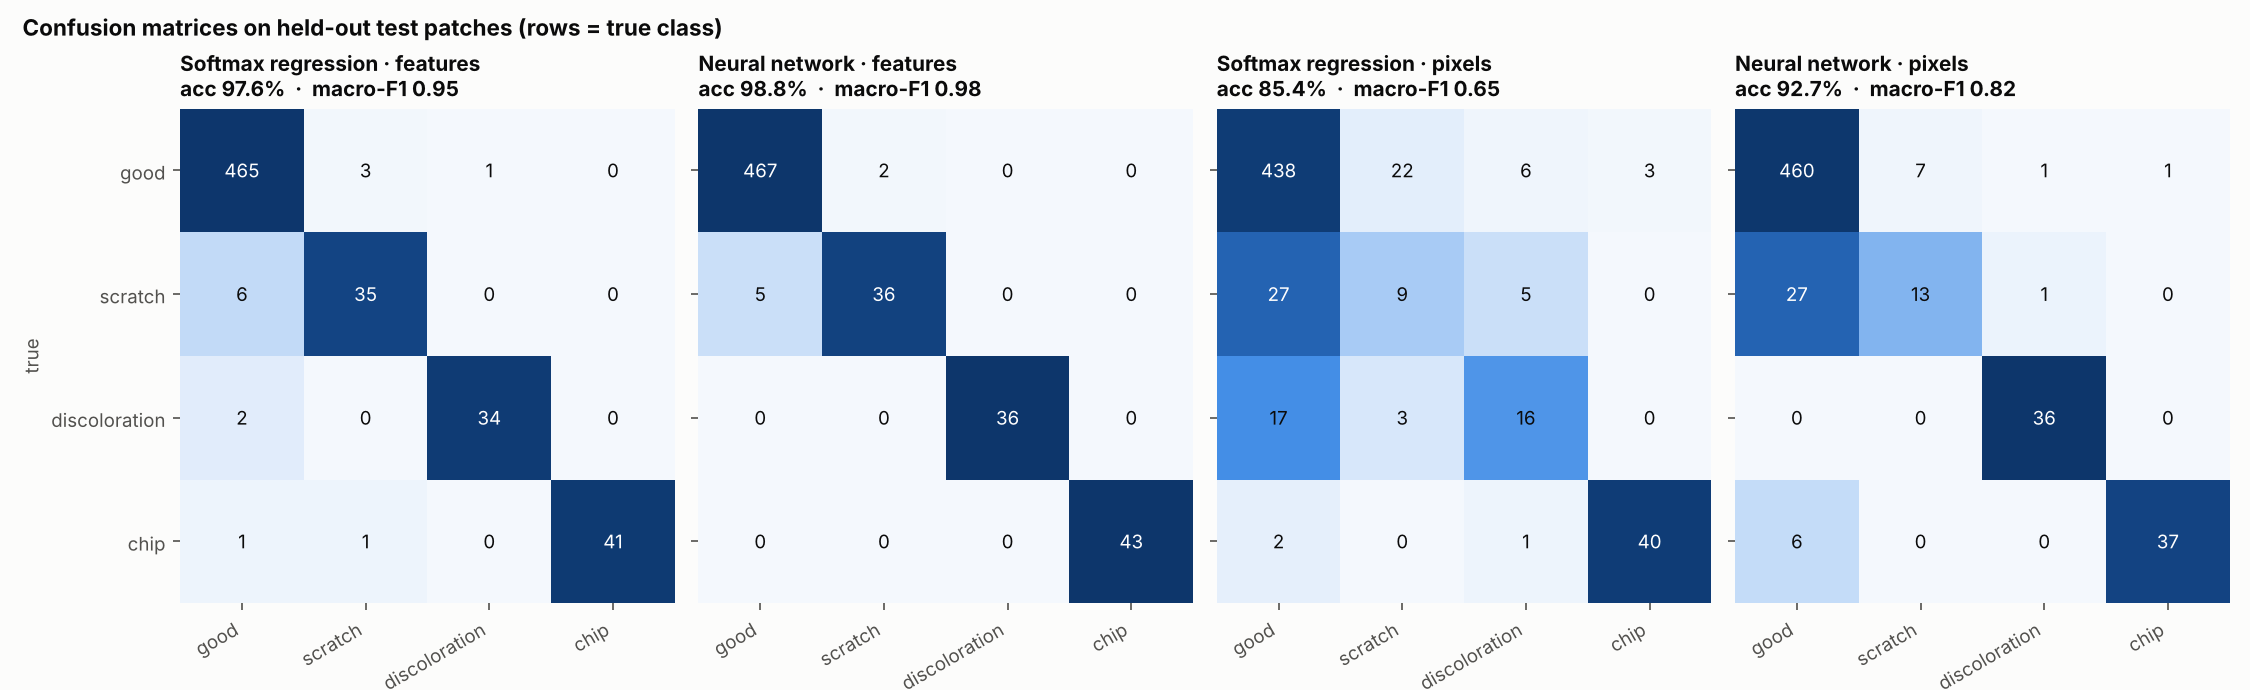

In [8]:
from IPython.display import Image, display
display(Image(filename=str(RUN / "confusion_matrices.png"), width=1000))

**Reading the results.**
* With **engineered features**, the problem is nearly linear: 76 softmax parameters get within about a point of the neural network.
* With **raw pixels**, softmax regression falls apart (it can't express "a thin line at any angle"), while the network recovers much of the structure. Scratches stay the hardest class from pixels, because a 1–3 px line almost disappears when the patch is downsampled to 24×24.
* **Calibration error (ECE)** is low for the feature models. That matters, because the verifier's decision uses the predicted probability, not just the label.

The softmax weights can be read like logistic-regression coefficients, and they match how each defect is physically produced:

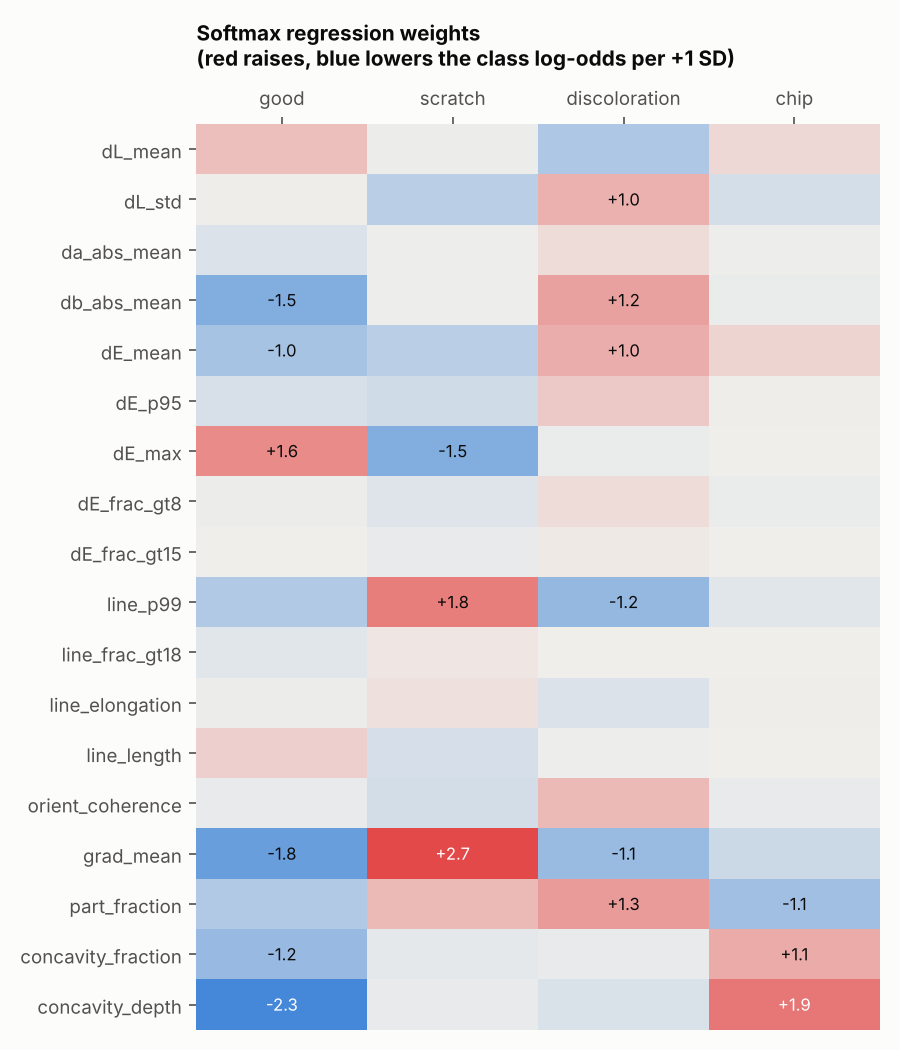

In [9]:
display(Image(filename=str(RUN / "softmax_coefficients.png"), width=480))

## 4. Is the neural network *really* better? Repeated grouped cross-validation

The single train/test split above gives one score per model, and McNemar's test on it was borderline (p ≈ 0.02) for the two feature models. One split can be lucky. Here I use **5-fold cross-validation, repeated twice**, with folds made of whole images, and compare models pair by pair across the same folds.

A naive paired t-test on CV folds is **over-confident**: the training sets overlap between folds, so fold scores are not independent. The **corrected resampled t-test** (Nadeau & Bengio, 2003) inflates the variance by $(1/J + n_{test}/n_{train})$ to account for this.

In [10]:
t0 = time.time()
cv = validation.repeated_cv(ps, mltrain.model_factories(), k=5, repeats=2, seed=SEED)
print(f"20 folds x 4 models in {time.time()-t0:.0f}s\n")
summ = validation.summarise_cv(cv)
for k, v in summ.items():
    print(f"{k:18s} macro-F1 {v['mean']:.3f} ± {v['sd']:.3f}  (range {v['min']:.3f}–{v['max']:.3f})")
nt, ne = np.mean(cv["n_train"]), np.mean(cv["n_test"])
print()
tests = {}
for a, b in [("mlp_features", "softmax_features"), ("mlp_pixels", "softmax_pixels"), ("mlp_features", "mlp_pixels")]:
    r = validation.corrected_resampled_ttest(cv["scores"][a]["macro_f1"], cv["scores"][b]["macro_f1"], nt, ne)
    tests[(a, b)] = r
    print(f"{a} − {b}: Δ = {r['mean_diff']:+.3f}   corrected p = {r['p_value']:.2g}   (naive p = {r['naive_p_value']:.2g})")

20 folds x 4 models in 253s

softmax_features   macro-F1 0.973 ± 0.013  (range 0.946–0.987)
mlp_features       macro-F1 0.982 ± 0.006  (range 0.969–0.990)
softmax_pixels     macro-F1 0.662 ± 0.028  (range 0.621–0.704)
mlp_pixels         macro-F1 0.824 ± 0.026  (range 0.775–0.856)



mlp_features − softmax_features: Δ = +0.008   corrected p = 0.13   (naive p = 0.013)
mlp_pixels − softmax_pixels: Δ = +0.162   corrected p = 7.5e-06   (naive p = 3.6e-08)
mlp_features − mlp_pixels: Δ = +0.157   corrected p = 1.8e-06   (naive p = 8.1e-09)


In [11]:
names = list(summ)
titles = {"softmax_features": "Softmax · features", "mlp_features": "Neural net · features",
          "softmax_pixels": "Softmax · pixels", "mlp_pixels": "Neural net · pixels"}
fig, ax = plt.subplots(figsize=(8, 3.2))
for i, n in enumerate(names):
    s = np.array(cv["scores"][n]["macro_f1"])
    y = len(names) - 1 - i
    ax.scatter(s, y + np.random.default_rng(i).uniform(-0.15, 0.15, len(s)), s=18, color=BLUE, alpha=0.6, lw=0)
    ax.plot([s.mean()] * 2, [y - 0.3, y + 0.3], color=INK, lw=2)
    ax.text(s.mean(), y + 0.38, f"{s.mean():.3f}", ha="center", fontsize=8, color=INK)
ax.set_yticks(range(len(names))[::-1], [titles[n] for n in names])
ax.set_xlabel("macro-F1 on held-out fold"); ax.grid(axis="x", color=GRID, lw=0.6)
ax.set_title("Repeated grouped 5-fold CV (dots = folds, bar = mean)", loc="left")
fig.tight_layout(); save(fig, "cv_scores.png")

**This is the key statistical result of the project.**
* **Pixels:** the neural network beats softmax regression by a large, highly significant margin. Non-linearity really helps when the model has to learn its own features.
* **Features:** the neural network's edge over softmax is **small and not statistically significant** after the correction, even though the naive test (and the single-split McNemar test) said it was. So the honest conclusion is that with good features, the simpler, interpretable model is just as good, and the extra complexity isn't justified by this evidence.

## 5. How much labelled data is needed?

Labelling real images is expensive, so I retrain the feature models on random subsets of the training images (3 repeats each) and score them on the fixed test set.

In [12]:
fac = {k: v for k, v in mltrain.model_factories().items() if k.endswith("features")}
lc = validation.learning_curve(train, test, fac, n_images=[10, 20, 40, 80, 160, 240], repeats=3, seed=SEED)
fig, ax = plt.subplots(figsize=(7, 3.6))
for (name, r), col in zip(lc.items(), [BLUE, ORANGE]):
    x, m, s = np.array(r["n_images"]), np.array(r["mean"]), np.array(r["sd"])
    ax.plot(x, m, "-o", color=col, lw=2, ms=6, mec=SURFACE, mew=1.5, label=titles[name])
    ax.fill_between(x, m - s, m + s, color=col, alpha=0.15, lw=0)
ax.set_xscale("log"); ax.set_xticks(x, x)
ax.set_xlabel("labelled training images"); ax.set_ylabel("test macro-F1")
ax.grid(color=GRID, lw=0.6); ax.legend(frameon=False, loc="lower right")
ax.set_title("Learning curve (band = ±1 SD over 3 random subsets)", loc="left")
fig.tight_layout(); save(fig, "learning_curve_data.png")
for name, r in lc.items():
    print(f"{titles[name]:22s}", "  ".join(f"n={n}: {m:.3f}" for n, m in zip(r["n_images"], r["mean"])))

Softmax · features     n=10: 0.886  n=20: 0.918  n=40: 0.927  n=80: 0.947  n=160: 0.950  n=240: 0.949
Neural net · features  n=10: 0.883  n=20: 0.936  n=40: 0.944  n=80: 0.955  n=160: 0.967  n=240: 0.971


With only 10 images, the two models are equal and very uncertain. **Softmax regression levels off at about 80 images** (macro-F1 ≈ 0.95), while **the neural network keeps improving** up to the full 240 (≈ 0.97). This is the classic bias–variance picture: the more flexible model needs more data, but it gets more out of it. For a real line, this suggests a first labelling budget in the low hundreds of images, rather than thousands, when good features are available.

## 6. Decision analysis: which threshold, and what is it worth?

A threshold is a **business decision**. Passing a defective part to a customer (an *escape*) costs far more than scrapping a good part (a *false reject*). I assume:

* escape cost **$100** (returns, warranty, reputation), false-reject cost **$5** (material + rework), and
* a production defect rate of **π = 5%**.

That defect rate matters. The labelled dataset is about 70% defective, because it was deliberately enriched with defects. Optimising cost on that mix would wrongly favour "reject everything". So expected cost is **re-weighted to the production rate**:

$$\text{cost per part} = c_{esc}\,\pi\,\text{FNR} + c_{fr}\,(1-\pi)\,\text{FPR}$$

Each image gets a risk score, the maximum P(defect) over its candidates. The threshold is chosen on **validation** images and evaluated on **test** images.

In [13]:
CE, CF, PI = 100.0, 5.0, 0.05
sens = InspectionConfig.from_json(ROOT / "configs" / "high_sensitivity.json")
ins = Inspector(sens, PatchClassifier.load(RUN / "mlp_features.npz"))
val_names, test_names = sorted(set(val.image)), sorted(set(test.image))
yv, sv = decision.image_scores(DATA, val_names, ins)
yt, st = decision.image_scores(DATA, test_names, ins)
t_star = decision.best_threshold(yv, sv, CE, CF, PI)
base = Inspector()
flag_rules = np.array([base.inspect(load_image(DATA / "images" / n)).verdict == "FAIL" for n in test_names])
fpr, tpr, _ = decision.roc_curve(yt, st)
print(f"Test ROC AUC = {decision.auc(fpr, tpr):.3f}   average precision = {decision.average_precision(yt, st):.3f}")
print(f"Cost-optimal threshold on validation: t* = {t_star:.2f}\n")
policies = {"Rules (default)": flag_rules, "Rules (high sensitivity)": st > 0, "High sensitivity + neural net (t*)": st >= t_star}
for k, f in policies.items():
    print(f"{k:36s} cost/part ${decision.expected_cost(yt, f, CE, CF, PI):.3f}   "
          f"escapes {int((yt & ~f).sum())}/{int(yt.sum())}   false rejects {int((~yt & f).sum())}/{int((~yt).sum())}")
sav = decision.paired_bootstrap_saving(yt, flag_rules, st >= t_star, CE, CF, PI, seed=SEED)
print(f"\nSaving vs default rules: ${sav['saving_per_part']:.2f} per part, 95% bootstrap CI [${sav['ci95'][0]:.2f}, ${sav['ci95'][1]:.2f}]")
print(f"At 1,000,000 parts/year that is about ${sav['saving_per_part']*1e6:,.0f} per year (CI ${sav['ci95'][0]*1e6:,.0f}–${sav['ci95'][1]*1e6:,.0f}).")

Test ROC AUC = 0.982   average precision = 0.993
Cost-optimal threshold on validation: t* = 0.50

Rules (default)                      cost/part $0.965   escapes 11/57   false rejects 0/23
Rules (high sensitivity)             cost/part $2.153   escapes 1/57   false rejects 10/23
High sensitivity + neural net (t*)   cost/part $0.263   escapes 3/57   false rejects 0/23

Saving vs default rules: $0.70 per part, 95% bootstrap CI [$0.26, $1.23]
At 1,000,000 parts/year that is about $701,754 per year (CI $260,965–$1,228,070).


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ax = axes[0]
ax.plot(fpr, tpr, color=BLUE, lw=2, drawstyle="steps-post"); ax.plot([0, 1], [0, 1], color=GRID, lw=1, ls="--")
ax.set_xlabel("false-positive rate (good parts rejected)"); ax.set_ylabel("true-positive rate (defects caught)")
ax.set_title(f"ROC curve · AUC {decision.auc(fpr, tpr):.3f}", loc="left"); ax.grid(color=GRID, lw=0.6)

ax = axes[1]
t, c = decision.cost_curve(yv, sv, CE, CF, PI)
ax.plot(t, c, color=BLUE, lw=2)
ax.axvline(t_star, color=INK2, lw=1, ls="--"); ax.text(t_star, ax.get_ylim()[1] * 0.92, f"  t* = {t_star:.2f}", color=INK2, fontsize=9)
ax.set_xlabel("verifier threshold on P(defect)"); ax.set_ylabel("expected cost per part ($)")
flat = t[np.isclose(c, c.min())]
ax.set_title(f"Validation cost curve: optimal for any t in [{flat.min():.2f}, {flat.max():.2f}]", loc="left"); ax.grid(color=GRID, lw=0.6)

ax = axes[2]
ratios = np.logspace(0, 3, 40)
for (k, f), col in zip(policies.items(), [ORANGE, AQUA, BLUE]):
    ax.plot(ratios, [decision.expected_cost(yt, f, r, 1.0, PI) for r in ratios], color=col, lw=2, label=k)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("escape cost ÷ false-reject cost"); ax.set_ylabel("cost per part (units of false-reject cost)")
ax.set_title("Which policy is cheapest? (π = 5%, test set)", loc="left"); ax.grid(color=GRID, lw=0.6)
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout(); save(fig, "decision_analysis.png")

# Where does "catch everything" (high-sensitivity rules alone) become cheaper than the verifier?
c_v = [decision.expected_cost(yt, st >= t_star, r, 1.0, PI) for r in ratios]
c_s = [decision.expected_cost(yt, st > 0, r, 1.0, PI) for r in ratios]
cross = next((r for r, a, b_ in zip(ratios, c_v, c_s) if b_ < a), None)
print(f"Optimal-threshold plateau on validation: [{flat.min():.2f}, {flat.max():.2f}]")
print(f"High-sensitivity rules alone become cheaper than the verifier once an escape costs more than ~{cross:.0f}x a false reject")

Optimal-threshold plateau on validation: [0.01, 0.99]
High-sensitivity rules alone become cheaper than the verifier once an escape costs more than ~242x a false reject


**Business interpretation.**
* The verifier ranks images almost perfectly (high AUC), and its scores sit near 0 or 1. As a result, the cost-optimal threshold is a wide plateau, so the decision is **robust** to the exact threshold and to moderate errors in the cost assumptions.
* The verifier **dominates the default rules** at every cost ratio: it misses fewer defects and rejects no more good parts.
* **The best policy depends on the cost ratio.** For ordinary parts, the verifier is cheapest. But if an escape costs a few hundred times more than a false reject (safety-critical parts such as brake or aerospace components), it becomes cheaper to run high-sensitivity rules alone and accept the scrap. In that case the verifier's threshold should be lowered, not removed. This is the kind of trade-off a data scientist should make visible to the business instead of hiding in a default.
* The saving is expressed **per part with a confidence interval**, which is the form a plant manager can put into an investment case. The interval is wide because the test set is small, which is a reason to validate on real images before deploying.

## 7. Monitoring the process: statistical process control

The inspector judges each part. Quality engineering also needs to know when the **process** changes (tool wear, a new material lot). I simulate 30 production batches of 25 parts, all inspected by the deployed system (high-sensitivity rules + neural net). The defect rate is 8% until batch 18, then rises to 22% (more scratches, as with a wearing tool).

A **p-chart** plots the fraction rejected per batch. Its limits are estimated from the first 15 in-control batches (Phase I): $\bar p \pm 3\sqrt{\bar p(1-\bar p)/n}$. It signals on a point above the upper limit, or on 8 consecutive points above the centre line.

In [15]:
deployed = Inspector(sens, PatchClassifier.load(ROOT / "models" / "mlp_features.npz"))
run = spc.simulate_production(deployed, n_batches=30, batch_size=25, shift_at=18, seed=SEED)
chart = spc.p_chart(run.rejected, run.batch_size, phase1=15)
gap = int(np.abs(run.rejected - run.true_defective).sum())
print(f"Per-batch reject counts differ from true defect counts by {gap} part(s) in total, out of {run.batch_size * len(run.rejected)} inspected")
print(f"centre {chart['center']:.3f}, UCL {chart['ucl']:.3f}; shift at batch {run.shift_at}, first signal at batch {chart['first_signal']}")

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
b = np.arange(len(chart["p"]))
ax.axvspan(run.shift_at - 0.5, len(b) - 0.5, color=GRID, alpha=0.5, lw=0)

ax.plot(b, chart["p"], "-o", color=BLUE, lw=2, ms=5, mec=SURFACE, mew=1.5)
sig = sorted(set(chart["beyond_limits"]) | set(chart["run_of_8"]))
ax.plot(b[sig], chart["p"][sig], "o", color=ORANGE, ms=9, mec=SURFACE, mew=1.5, label="out-of-control signal")
for yv_, lab in [(chart["center"], "centre line"), (chart["ucl"], "UCL (3σ)")]:
    ax.axhline(yv_, color=INK2, lw=1, ls="--" if lab != "centre line" else "-")
    ax.text(len(b) - 0.4, yv_, f" {lab}", va="center", color=INK2, fontsize=8)
ax.axvline(14.5, color=INK2, lw=0.8, ls=":"); ax.text(14.3, ax.get_ylim()[1] * 0.97, "Phase I: limits estimated ", ha="right", va="top", fontsize=8, color=INK2)
ax.text(run.shift_at - 0.3, ax.get_ylim()[1] * 0.97, " process degrades →", color=INK2, fontsize=9, va="top")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_xlabel("production batch")
ax.set_ylabel("parts rejected"); ax.set_xlim(-0.5, len(b) + 2.5); ax.legend(frameon=False, loc="upper left")
ax.set_title("p-chart of the inspector's reject rate", loc="left")

types = sorted(run.defect_counts, key=run.defect_counts.get, reverse=True)
vals = np.array([run.defect_counts[t] for t in types]); cum = vals.cumsum() / vals.sum()
ax2.bar(types, vals, color=BLUE, edgecolor=SURFACE, linewidth=2)
for i, v in enumerate(vals): ax2.text(i, v, f"{v}", ha="center", va="bottom", fontsize=9)
ax2b = ax2.twinx(); ax2b.plot(types, cum, "-o", color=INK2, lw=1.5, ms=5); ax2b.set_ylim(0, 1.05)
ax2b.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax2b.spines["right"].set_visible(True)
ax2.set_title("Pareto of detected defects", loc="left"); ax2.set_ylabel("defects detected")
fig.tight_layout(); save(fig, "spc_pchart.png")

Per-batch reject counts differ from true defect counts by 1 part(s) in total, out of 750 inspected
centre 0.085, UCL 0.253; shift at batch 18, first signal at batch 22


The chart stays in control during Phase I and signals a few batches after the process degrades. The Pareto chart shows **scratches** as the dominant defect type, which points maintenance at the cutting tool. The inspector produces the per-part decisions, and SPC turns them into a process-level warning.

## 8. Conclusions

1. **The rule-based baseline can't solve the problem by tuning thresholds alone:** it either misses faint defects or rejects good parts.
2. **A learned verifier fixes the trade-off.** High-sensitivity rules followed by a classifier cut false rejects from ~43% to ~0% while keeping most of the sensitivity.
3. **Model choice should follow the evidence.** On raw pixels, the neural network is clearly needed. On engineered features, its advantage over softmax regression **does not survive** a correctly specified significance test, so the simpler, interpretable model is a defensible choice.
4. **Decisions should be priced.** With stated cost assumptions and a realistic defect rate, the verifier saves money per part, with a bootstrap CI, and the decision is robust to the exact threshold.
5. **Statistical process control** turns per-part verdicts into early warning of process drift.

**Limitations.** The data is synthetic, the test set is small (80 images), and the cost figures are assumptions. Next steps: validate on labelled real images, train a CNN on full-resolution patches for comparison under the same CV protocol, and estimate the p-chart's average run length to detection.

In [16]:
print(f"Notebook finished. Figures saved to {FIG.relative_to(ROOT)}/")

Notebook finished. Figures saved to docs/figures/
